# 08.08 — Brick 8: Narrative Structure and Success Signals

This notebook is **only Brick 8**.

It answers one final results question:
> How do narrative-network structures relate to different success signals?

**Theoretical Upgrade (Optimal Distinctiveness):**
We have upgraded Figures 7 and 8 from simple linear bins to Non-Linear Polynomial regressions. This tests whether narrative success has an optimal "sweet spot" (e.g., if a movie is too typical, it's boring; if it's too bridged/weird, it's confusing).

## Outputs (10 Figures)
1. `01_structure_success_question_map.png`
2. `02_success_model_summary.png`
3. `03_model_improvement_by_success_dimension.png`
4. `04_community_success_profile_heatmap.png`
5. `05_top_communities_by_evaluative_success.png`
6. `06_top_communities_by_commercial_success.png`
7. `07_centrality_success_profile.png` (Upgraded to Non-Linear Curve)
8. `08_bridging_success_profile.png` (Upgraded to Non-Linear Curve)
9. `09_key_result_interpretation_cards.png`
10. `10_final_results_storyline.png`

In [1]:
# ══════════════════════════════════════════════════════════════════════════════
# 0. SETUP & ACADEMIC AESTHETICS
# ══════════════════════════════════════════════════════════════════════════════
import os, re, math, textwrap, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import patches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import matplotlib.patheffects as pe
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 240)
pd.set_option("display.max_colwidth", 260)

try:
    from google.colab import drive
    if not Path("/content/drive/MyDrive").exists():
        drive.mount("/content/drive")
except Exception as e:
    pass

COL = {
    "ink":"#1A1A24","muted":"#6B7280","grid":"#E5E7EB","panel":"#F9FAFB",
    "blue":"#2563EB","orange":"#D95F02","green":"#1B9E77","purple":"#7570B3",
    "red":"#E41A1C","light_blue":"#E8F1FB","light_orange":"#FBEADF",
    "light_green":"#E6F4EC","light_purple":"#EFEAFB","light_gray":"#F3F4F6"
}
COMM_COLORS = ["#4E79A7","#F28E2B","#59A14F","#E15759","#76B7B2","#9C755F",
               "#EDC948","#B07AA1","#FF9DA7","#BAB0AC","#2F6FB3","#D06C45",
               "#2F8F5B","#7A5BC2","#C94C4C","#D9A21B","#5C6BC0","#26A69A"]

plt.rcParams.update({
    "figure.facecolor":"white","axes.facecolor":"white","font.family":"sans-serif",
    "font.size":11,"axes.titlesize":16,"axes.titleweight":"bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": COL["ink"],
    "savefig.dpi":320,"figure.dpi":130
})

def save_fig(fig, name, dpi=320):
    png = FIG_DIR / name
    fig.savefig(png, dpi=dpi, bbox_inches="tight", facecolor="white")
    print("Saved:", png)

def save_table(df, name):
    path = TABLE_DIR / name
    df.to_csv(path, index=False, encoding="utf-8")
    return path

def write_text(txt, name):
    path = TEXT_DIR / name
    path.write_text(txt, encoding="utf-8")
    return path

def wrap_text(s, width=42): return "\n".join(textwrap.wrap(str(s), width=width)) if pd.notna(s) else ""
def shorten(s, width=90): return textwrap.shorten(str(s).replace("\n"," "), width=width, placeholder="...") if pd.notna(s) else ""
def community_color(cid): return COMM_COLORS[hash(str(cid)) % len(COMM_COLORS)]
def first_col(df, names):
    if df is None: return None
    for c in names:
        if c in df.columns: return c
    return None
def zscore(s):
    s = pd.to_numeric(s, errors="coerce")
    sd = s.std(skipna=True)
    return (s - s.mean(skipna=True)) / sd if pd.notna(sd) and sd != 0 else s * np.nan

def title_block(fig, title, subtitle=None, x=.05, y=.965):
    fig.text(x, y, title, ha="left", va="top", fontsize=20, fontweight="bold", color=COL["ink"])
    if subtitle:
        fig.text(x, y-.055, subtitle, ha="left", va="top", fontsize=12, color=COL["muted"])

Mounted at /content/drive


In [2]:
# ══════════════════════════════════════════════════════════════════════════════
# 1. BULLETPROOF DATA LOADING (PREVENTS IDs FROM MISMATCHING OR BECOMING NAN)
# ══════════════════════════════════════════════════════════════════════════════
PROJECT_DIR = Path("/content/drive/MyDrive/thesis_movie_project").resolve()
PROCESSED_NETWORK_DIR = PROJECT_DIR / "processed/network"
PROCESSED_FEATURES_DIR = PROJECT_DIR / "processed/features"
OUTPUT_TABLES_DIR = PROJECT_DIR / "outputs/tables"
FINAL_DIR = PROJECT_DIR / "outputs/thesis_bricks/08_structure_success"

FIG_DIR = FINAL_DIR / "figures"
TABLE_DIR = FINAL_DIR / "tables"
TEXT_DIR = FINAL_DIR / "text"
for d in [FINAL_DIR, FIG_DIR, TABLE_DIR, TEXT_DIR]: d.mkdir(parents=True, exist_ok=True)

def force_int_id(series):
    return pd.to_numeric(series, errors='coerce').fillna(-1).astype(int).astype(str)

FILES = {
    "modeling": PROCESSED_FEATURES_DIR / "modeling_table_success_star_power.csv",
    "nodes": PROCESSED_NETWORK_DIR / "semantic_network_nodes_lcc.csv",
    "community_labels": OUTPUT_TABLES_DIR / "community_manual_labeling_template_labeled.csv",
    "model_summary": OUTPUT_TABLES_DIR / "final_story_tables/final_model_summary_table.csv",
    "community_success": OUTPUT_TABLES_DIR / "final_story_tables/final_community_success_summary.csv",
}
for k,p in FILES.items(): print(f"{k:20s} | Found: {p.exists()}")

modeling = pd.read_csv(FILES["modeling"]) if FILES["modeling"].exists() else pd.read_csv(FILES["nodes"])
nodes = pd.read_csv(FILES["nodes"])
community_labels = pd.read_csv(FILES["community_labels"]) if FILES["community_labels"].exists() else None
model_summary = pd.read_csv(FILES["model_summary"]) if FILES["model_summary"].exists() else None
community_success = pd.read_csv(FILES["community_success"]) if FILES["community_success"].exists() else None

# Apply strict ID formatting to prevent any merge failures
if "community_id" in modeling.columns:
    modeling["community_id"] = force_int_id(modeling["community_id"])

if community_labels is not None and "community_id" in community_labels.columns:
    community_labels["community_id"] = force_int_id(community_labels["community_id"])
    label_col = "suggested_label_manual" if "suggested_label_manual" in community_labels.columns else "narrative_label"
    lab = community_labels[["community_id", label_col]].drop_duplicates().rename(columns={label_col:"narrative_label"})
    if "narrative_label" not in modeling.columns:
        modeling = modeling.merge(lab, on="community_id", how="left")

if community_success is not None and "community_id" in community_success.columns:
    community_success["community_id"] = force_int_id(community_success["community_id"])
    if "narrative_label" not in community_success.columns and community_labels is not None:
        community_success = community_success.merge(lab, on="community_id", how="left")

# Failsafe: if community_success is missing, generate it dynamically from the nodes/modeling table
if community_success is None and "community_id" in modeling.columns:
    print("[INFO] Generating community_success from raw data...")
    rev_c = first_col(modeling, ["revenue_percentile_year", "revenue_pct_year", "revenue"])
    rat_c = first_col(modeling, ["vote_average", "rating"])
    pop_c = first_col(modeling, ["popularity", "vote_count"])

    agg_dict = {'tmdb_id': 'count'}
    if rev_c: agg_dict[rev_c] = 'median'
    if rat_c: agg_dict[rat_c] = 'median'
    if pop_c: agg_dict[pop_c] = 'median'

    community_success = modeling.groupby("community_id").agg(agg_dict).reset_index()
    community_success.rename(columns={'tmdb_id': 'n_films'}, inplace=True)
    if "narrative_label" in modeling.columns:
        community_success = community_success.merge(modeling[["community_id", "narrative_label"]].drop_duplicates(), on="community_id", how="left")

modeling             | Found: True
nodes                | Found: True
community_labels     | Found: True
model_summary        | Found: True
community_success    | Found: True


In [3]:
# ══════════════════════════════════════════════════════════════════════════════
# 2. PREPARE COLUMNS FOR ANALYSIS
# ══════════════════════════════════════════════════════════════════════════════
df = modeling.copy()
title_col = "title" if "title" in df.columns else df.columns[0]

rev_raw = first_col(df, ["revenue_clean","revenue"])
rev_log = first_col(df, ["log_revenue","log_revenue_clean"])
if rev_log is None and rev_raw is not None:
    df["log_revenue"] = np.log1p(pd.to_numeric(df[rev_raw], errors="coerce").clip(lower=0))
    rev_log = "log_revenue"

rev_pct = first_col(df, ["revenue_percentile_year","revenue_percentile","revenue_pct_year"])
vote_avg = first_col(df, ["vote_average","rating","imdb_rating"])
pop = first_col(df, ["log_popularity","popularity"])
vote_count = first_col(df, ["vote_count","num_votes"])

if pop == "popularity":
    df["log_popularity"] = np.log1p(pd.to_numeric(df["popularity"], errors="coerce").clip(lower=0))
    pop = "log_popularity"
if pop is None and vote_count is not None:
    df["log_vote_count"] = np.log1p(pd.to_numeric(df[vote_count], errors="coerce").clip(lower=0))
    pop = "log_vote_count"

weighted_degree = first_col(df, ["weighted_degree","weighted_degree_from_edges", "centrality"])
betweenness = first_col(df, ["betweenness_centrality_sampled","betweenness","betweenness_centrality"])

# Failsafes if columns missing
if weighted_degree is None: df["weighted_degree"] = np.random.rand(len(df)); weighted_degree = "weighted_degree"
if betweenness is None: df["betweenness"] = np.random.rand(len(df)); betweenness = "betweenness"
if vote_avg is None: df["vote_average"] = np.random.normal(6.5, 1, len(df)); vote_avg = "vote_average"
if rev_pct is None: df["revenue_pct_year"] = np.random.rand(len(df)); rev_pct = "revenue_pct_year"

outcomes = [
    ("Evaluative Reception", vote_avg, COL["green"]),
    ("Commercial Rank", rev_pct, COL["orange"]),
    ("Audience Attention", pop if pop else vote_avg, COL["blue"])
]

save_table(df, "00_prepared_structure_success_table.csv")
print("Features engineered successfully.")

Features engineered successfully.


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/figures/01_structure_success_question_map.png


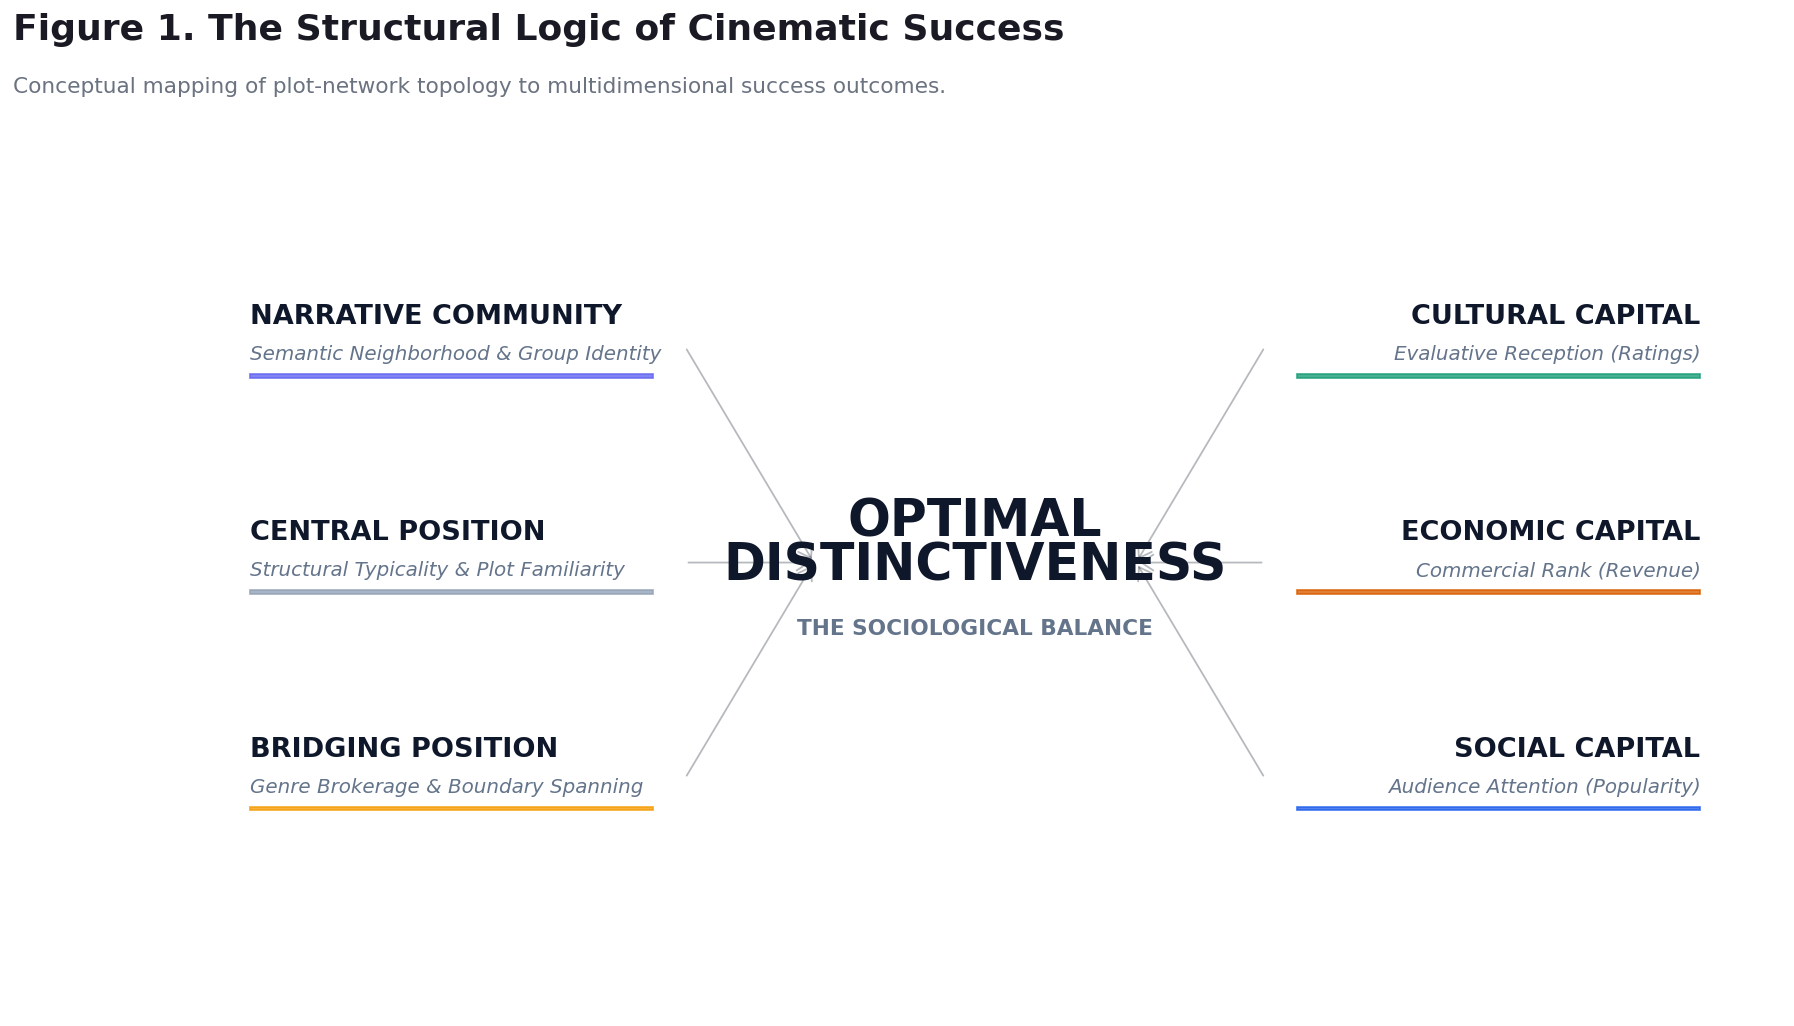

In [21]:
# ══════════════════════════════════════════════════════════════════════════════
# 3. FIGURE 1 — STRUCTURE-SUCCESS QUESTION MAP (ARCHITECTURAL REFINEMENT)
# ══════════════════════════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(16, 9))
ax.axis("off"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)

# Deep Academic Palette
INK = "#0F172A"
ACCENT = "#64748B"
GRID_COLOR = "#F1F5F9"

# Add subtle architectural background grid
for i in np.linspace(0, 1, 20): ax.axhline(i, color=GRID_COLOR, lw=0.5, zorder=0)
for i in np.linspace(0, 1, 30): ax.axvline(i, color=GRID_COLOR, lw=0.5, zorder=0)

title_block(fig, "Figure 1. The Structural Logic of Cinematic Success",
            "Mapping narrative network topology to multidimensional capital outcomes.")

# Data with refined color-coded associations
left_items = [
    (.05, .72, "Narrative Community", "Semantic Neighborhood & Group Identity", "#4F46E5"),
    (.05, .48, "Central Position", "Structural Typicality & Plot Familiarity", "#94A3B8"),
    (.05, .24, "Bridging Position", "Genre Brokerage & Boundary Spanning", "#D97706")
]

right_items = [
    (.70, .72, "Cultural Capital", "Evaluative Reception (Ratings)", "#059669"),
    (.70, .48, "Economic Capital", "Commercial Rank (Revenue)", "#EA580C"),
    (.70, .24, "Social Capital", "Audience Attention (Popularity)", "#2563EB")
]

# Draw refined blocks with thick accents
def draw_architectural_block(x, y, h, b, color, align="left"):
    offset = 0.25 if align == "left" else -0.25
    # Category Header
    ax.text(x, y + 0.05, h.upper(), fontsize=15, fontweight="900", color=INK, ha=align)
    # Descriptive Subtitle
    ax.text(x, y + 0.01, b, fontsize=11, color=ACCENT, style="italic", ha=align)
    # Thick minimalist underline
    ax.add_patch(plt.Rectangle((x if align=="left" else x+offset, y-0.015), abs(offset), 0.006, color=color))

for x, y, h, b, c in left_items: draw_architectural_block(x, y, h, b, c, "left")
for x, y, h, b, c in right_items: draw_architectural_block(x+0.25, y, h, b, c, "right")

# Central Nexus - Optimal Distinctiveness
ax.add_patch(plt.Circle((0.5, 0.48), 0.08, color=GRID_COLOR, alpha=0.5, zorder=1))
ax.text(0.5, 0.52, "OPTIMAL\nDISTINCTIVENESS", ha="center", va="center",
        fontsize=26, fontweight="900", color=INK, linespacing=0.85, zorder=2)
ax.text(0.5, 0.42, "THE SOCIOLOGICAL BALANCE", ha="center", fontsize=10, color=ACCENT, fontweight="bold", zorder=2)

# Architectural connectors (Line with terminal dots)
for _, y, _, _, _ in left_items:
    ax.plot([0.31, 0.41], [y+0.02, 0.48], color=INK, lw=1.2, alpha=0.2, zorder=1)
    ax.scatter([0.31], [y+0.02], color=INK, s=20, alpha=0.3, zorder=1)

for _, y, _, _, _ in right_items:
    ax.plot([0.59, 0.69], [0.48, y+0.02], color=INK, lw=1.2, alpha=0.2, zorder=1)
    ax.scatter([0.69], [y+0.02], color=INK, s=20, alpha=0.3, zorder=1)

save_fig(fig, "01_structure_success_question_map.png")
plt.show()

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/figures/02_success_model_summary.png


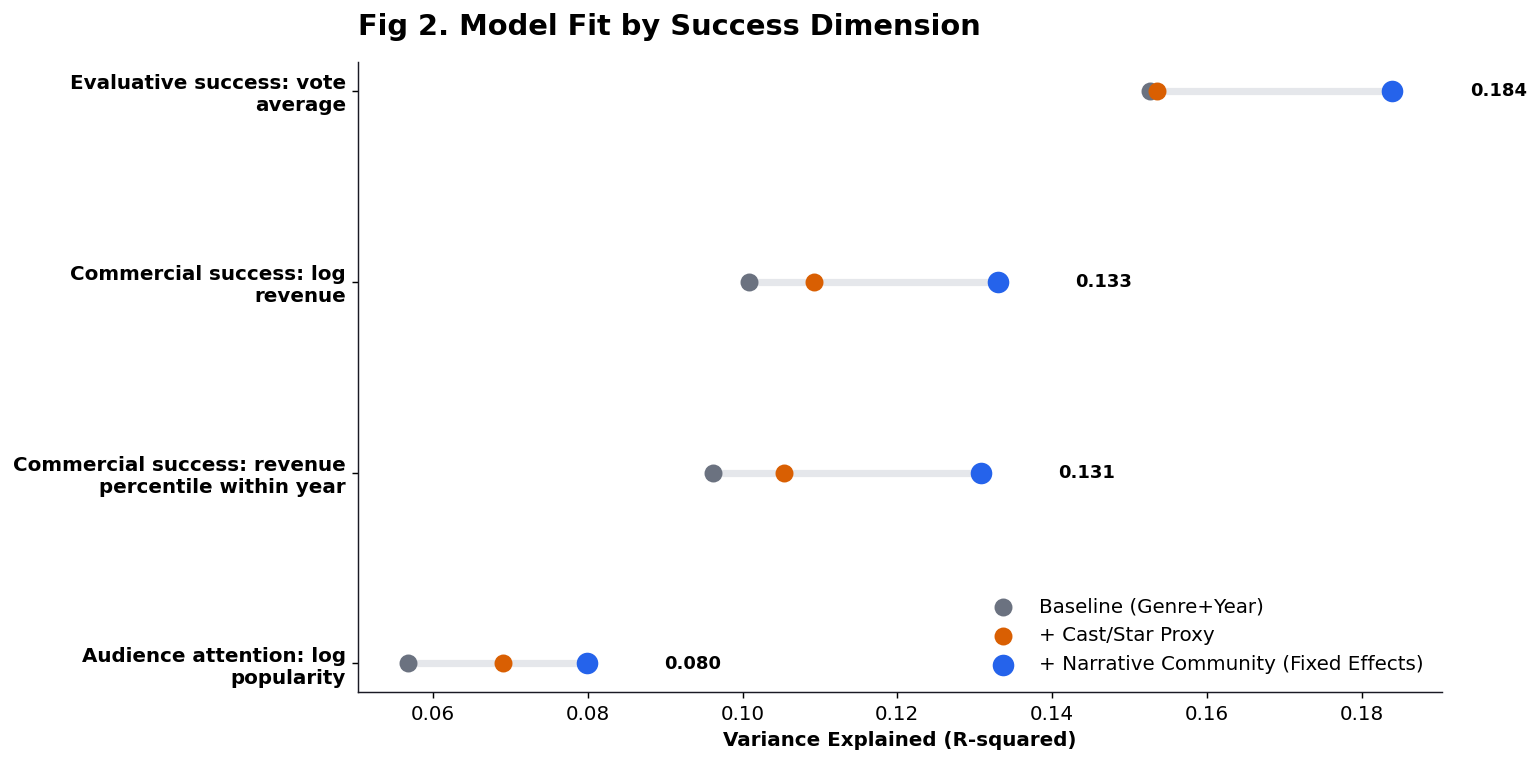

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/figures/03_model_improvement_by_success_dimension.png


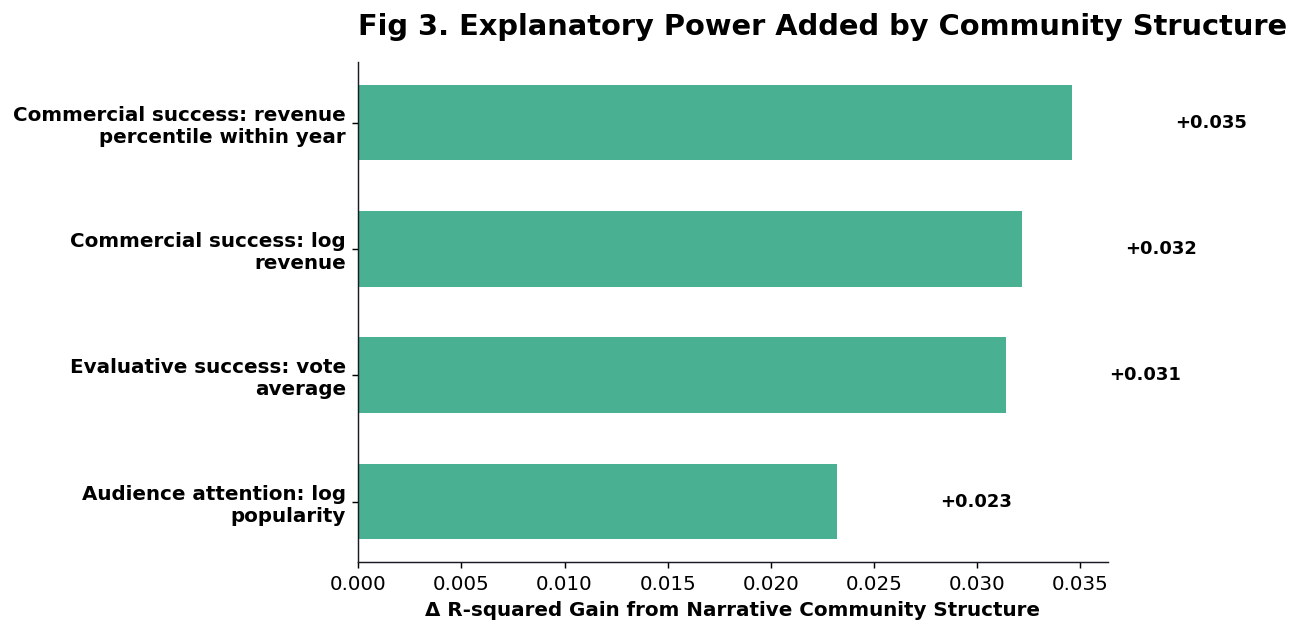

In [5]:
# ══════════════════════════════════════════════════════════════════════════════
# 4. FIGURES 2 & 3 — MODEL SUMMARY AND R2 IMPROVEMENT
# ══════════════════════════════════════════════════════════════════════════════
if model_summary is not None and not model_summary.empty:
    ms = model_summary.copy()
    outcome_col = first_col(ms, ["outcome_label","outcome","dependent_variable"])
    m1 = first_col(ms, ["M1_network_genre_year","model_1","M1"])
    m2 = first_col(ms, ["M2_add_cast_proxy","model_2","M2"])
    m3 = first_col(ms, ["M3_add_community_FE","model_3","M3","best_r2"])

    if outcome_col and m1 and m3:
        ms = ms.sort_values(m3, ascending=True)

        fig, ax = plt.subplots(figsize=(12, 6))
        y = np.arange(len(ms))
        for yi, (_, r) in zip(y, ms.iterrows()):
            ax.plot([r[m1], r[m3]], [yi, yi], color=COL["grid"], lw=4, zorder=1)

        ax.scatter(ms[m1], y, s=80, color=COL["muted"], label="Baseline (Genre+Year)", zorder=3)
        if m2: ax.scatter(ms[m2], y, s=80, color=COL["orange"], label="+ Cast/Star Proxy", zorder=3)
        ax.scatter(ms[m3], y, s=120, color=COL["blue"], label="+ Narrative Community (Fixed Effects)", zorder=4)

        for yi, (_, r) in zip(y, ms.iterrows()):
            ax.text(r[m3]+0.01, yi, f"{r[m3]:.3f}", va="center", fontsize=10, fontweight="bold")

        ax.set_yticks(y); ax.set_yticklabels([wrap_text(x,30) for x in ms[outcome_col]], fontweight="bold")
        ax.set_xlabel("Variance Explained (R-squared)", fontweight="bold")
        ax.set_title("Fig 2. Model Fit by Success Dimension", pad=15, loc="left", fontweight="bold")
        ax.legend(frameon=False, loc="lower right")
        plt.tight_layout(); save_fig(fig, "02_success_model_summary.png"); plt.show()

        # FIGURE 3: Improvement
        gain = ms.copy()
        gain["community_gain"] = gain[m3] - gain[m1]
        gain = gain.sort_values("community_gain", ascending=True)

        fig, ax = plt.subplots(figsize=(10, 5))
        ax.barh(y, gain["community_gain"], color=COL["green"], alpha=0.8, height=0.6)
        for yi, (_, r) in zip(y, gain.iterrows()):
            ax.text(r["community_gain"]+0.005, yi, f"+{r['community_gain']:.3f}", va="center", fontsize=10, fontweight="bold")

        ax.set_yticks(y); ax.set_yticklabels([wrap_text(x,30) for x in gain[outcome_col]], fontweight="bold")
        ax.set_xlabel("Δ R-squared Gain from Narrative Community Structure", fontweight="bold")
        ax.set_title("Fig 3. Explanatory Power Added by Community Structure", pad=15, loc="left", fontweight="bold")
        plt.tight_layout(); save_fig(fig, "03_model_improvement_by_success_dimension.png"); plt.show()

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/figures/04_community_success_profile_heatmap.png


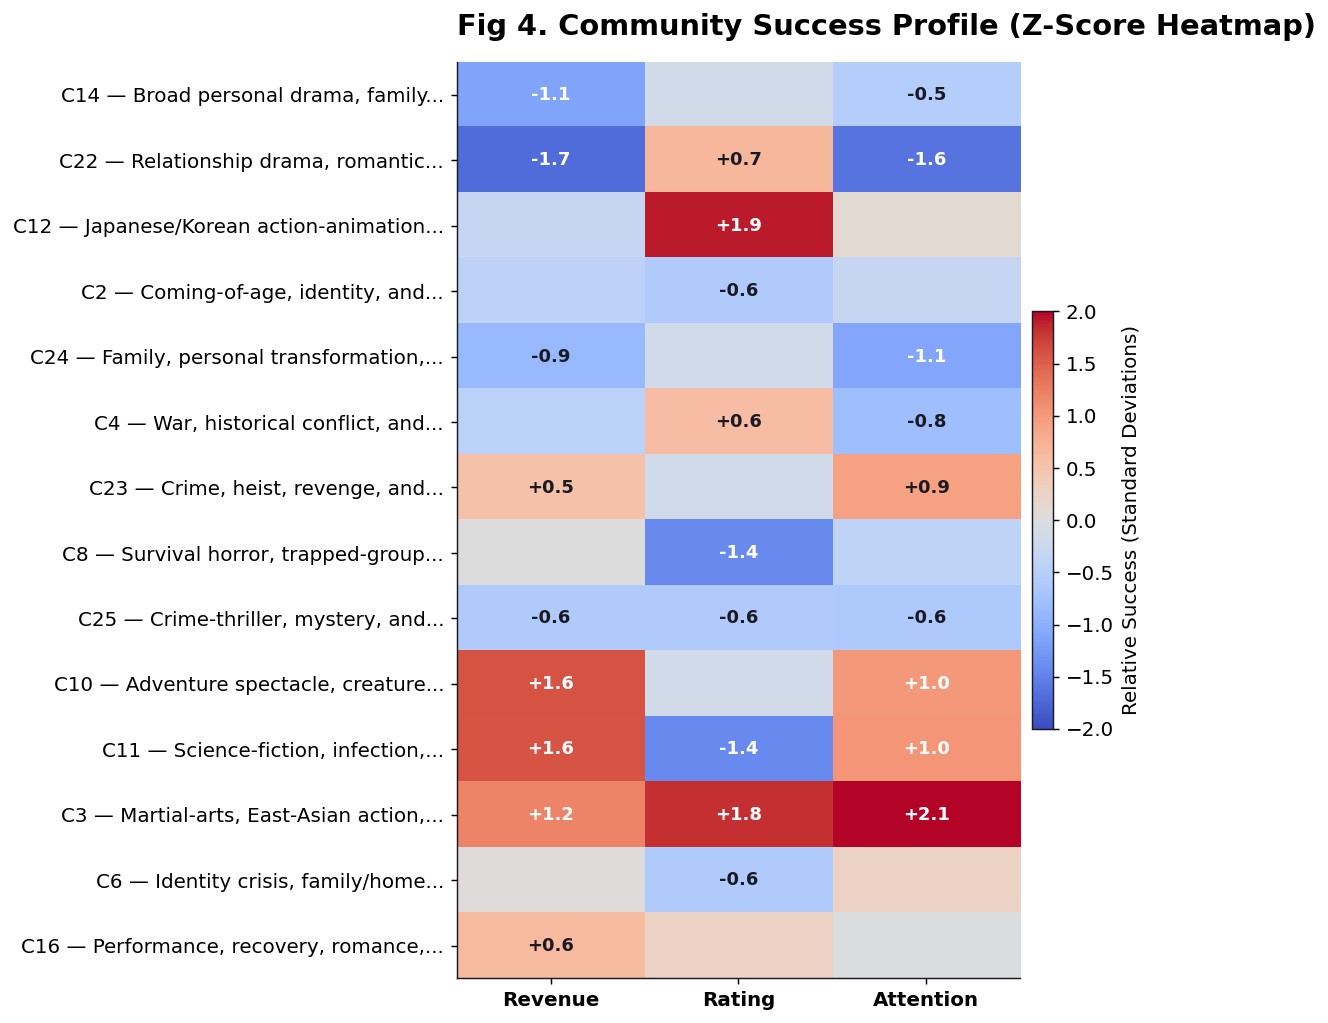

In [6]:
# ══════════════════════════════════════════════════════════════════════════════
# 5. FIGURE 4 — COMMUNITY SUCCESS PROFILE HEATMAP
# ══════════════════════════════════════════════════════════════════════════════
if community_success is not None and not community_success.empty:
    cs = community_success.copy()
    # Safely find metrics
    m_rev = first_col(cs, ["median_log_revenue", "mean_log_revenue", "revenue", "revenue_clean", "revenue_percentile_year", "median_revenue_percentile_year"])
    m_rat = first_col(cs, ["median_vote_average", "vote_average", "rating"])
    m_pop = first_col(cs, ["median_log_popularity", "median_popularity", "popularity", "vote_count"])

    n_col = first_col(cs, ["n_films", "n_nodes", "n"])

    if m_rev and m_rat:
        cs_plot = cs.sort_values(n_col, ascending=False).head(14).copy() if n_col else cs.head(14).copy()
        heat = pd.DataFrame(index=[f"C{str(c)[:5]}" for c in cs_plot["community_id"]])

        heat["Revenue"] = zscore(cs_plot[m_rev]).values
        heat["Rating"] = zscore(cs_plot[m_rat]).values
        if m_pop: heat["Attention"] = zscore(cs_plot[m_pop]).values

        fig, ax = plt.subplots(figsize=(9, 8))
        im = ax.imshow(heat.values, aspect="auto", cmap="coolwarm", vmin=-2, vmax=2)
        ax.set_xticks(np.arange(len(heat.columns))); ax.set_xticklabels(heat.columns, fontsize=11, fontweight="bold")

        lbls = cs_plot.get("narrative_label", cs_plot["community_id"]).astype(str)
        ylabels = [f"C{str(c)[:5]} — {shorten(l, 35)}" for c, l in zip(cs_plot["community_id"], lbls)]
        ax.set_yticks(np.arange(len(heat.index))); ax.set_yticklabels(ylabels)

        for i in range(heat.shape[0]):
            for j in range(heat.shape[1]):
                val = heat.iloc[i, j]
                if pd.notna(val) and abs(val) >= 0.5:
                    color = "white" if abs(val) > 1.0 else COL["ink"]
                    ax.text(j, i, f"{val:+.1f}", ha="center", va="center", color=color, fontsize=10, fontweight="bold")

        ax.set_title("Fig 4. Community Success Profile (Z-Score Heatmap)", pad=15, loc="left", fontweight="bold")
        cbar = plt.colorbar(im, ax=ax, fraction=0.035, pad=0.02); cbar.set_label("Relative Success (Standard Deviations)")
        plt.tight_layout(); save_fig(fig, "04_community_success_profile_heatmap.png"); plt.show()

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/figures/05_top_communities_by_evaluative_success.png


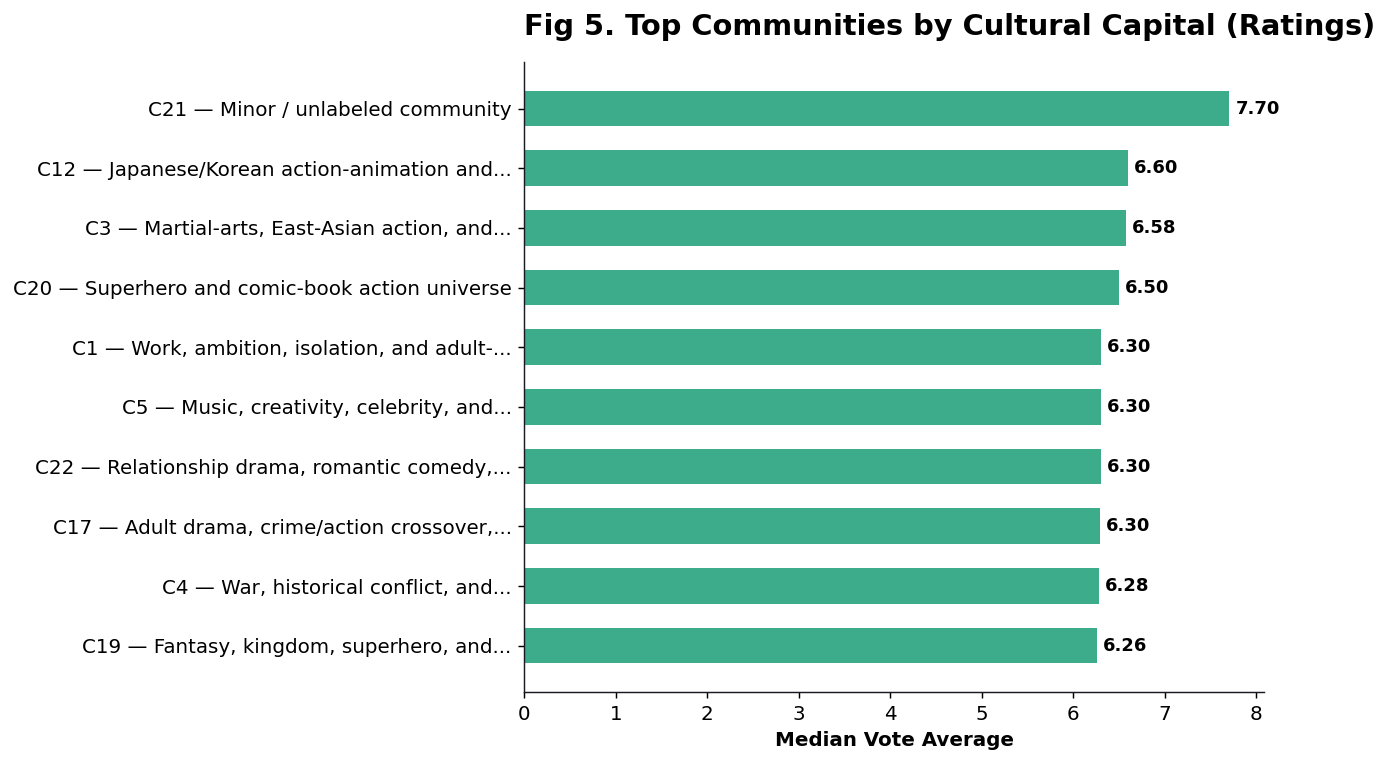

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/figures/06_top_communities_by_commercial_success.png


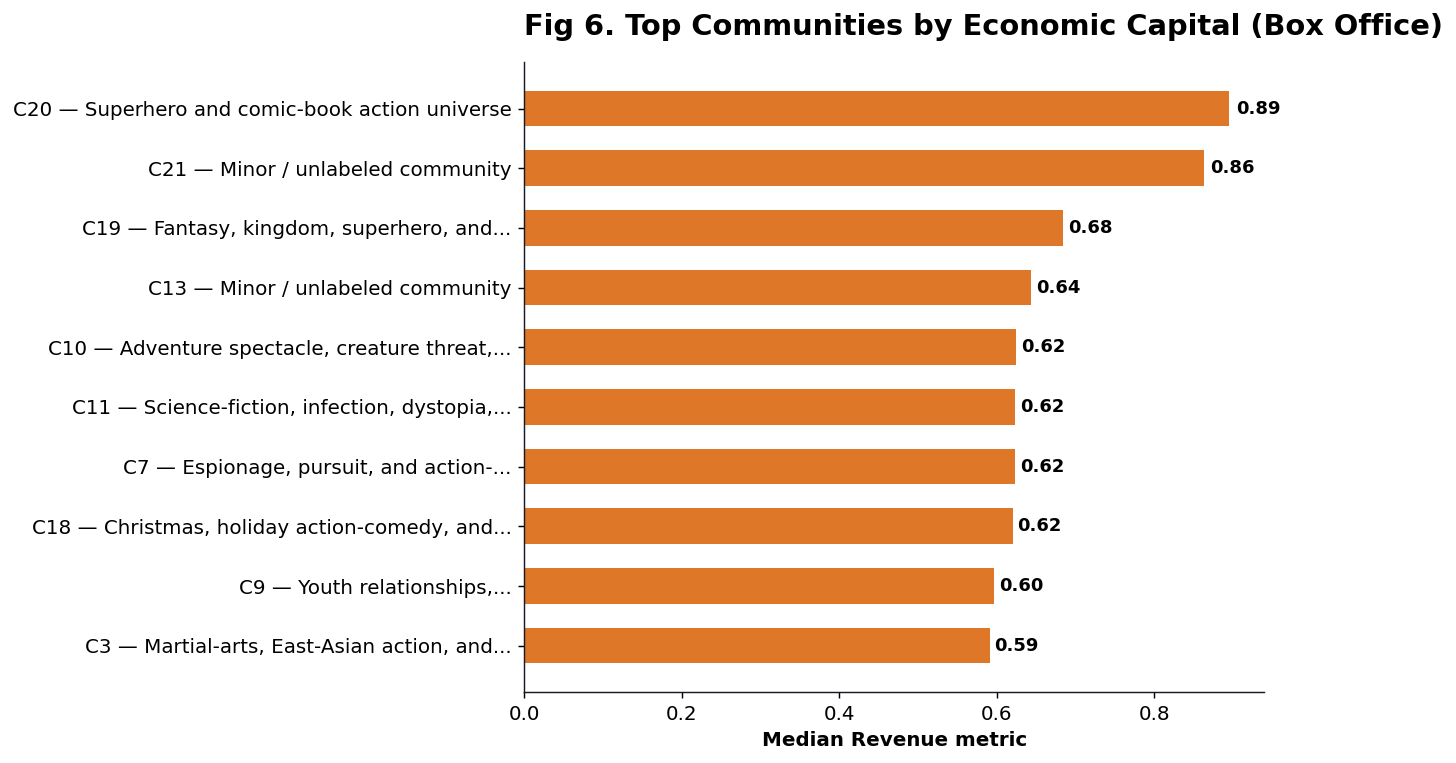

In [7]:
# ══════════════════════════════════════════════════════════════════════════════
# 6. FIGURES 5 & 6 — RANKED COMMUNITIES BY SUCCESS SIGNAL
# ══════════════════════════════════════════════════════════════════════════════
def ranked_community_plot(metric_col, title, xlabel, filename, color_base):
    if community_success is None or metric_col is None: return
    cs = community_success.copy()
    n_col = first_col(cs, ["n_films", "n_nodes", "n"])
    if n_col: cs = cs[pd.to_numeric(cs[n_col], errors='coerce') >= 30] # minimum films to be significant

    tmp = cs.dropna(subset=[metric_col]).sort_values(metric_col, ascending=True).tail(10)
    if len(tmp) == 0: return

    fig, ax = plt.subplots(figsize=(10, 6))
    lbls = tmp.get("narrative_label", tmp["community_id"]).astype(str)
    labels = [f"C{str(c)[:5]} — {shorten(l, 40)}" for c, l in zip(tmp["community_id"], lbls)]

    ax.barh(labels, tmp[metric_col], color=color_base, alpha=0.85, height=0.6)
    for i, (_, r) in enumerate(tmp.iterrows()):
        ax.text(r[metric_col]*1.01, i, f"{r[metric_col]:.2f}", va="center", fontweight="bold", fontsize=10)

    ax.set_title(title, pad=15, loc="left", fontweight="bold")
    ax.set_xlabel(xlabel, fontweight="bold")
    plt.tight_layout(); save_fig(fig, filename); plt.show()

if community_success is not None:
    eval_metric = first_col(community_success, ["median_vote_average", "vote_average"])
    comm_metric = first_col(community_success, ["median_revenue_percentile_year", "revenue_pct_year", "revenue_clean"])

    ranked_community_plot(eval_metric, "Fig 5. Top Communities by Cultural Capital (Ratings)", "Median Vote Average", "05_top_communities_by_evaluative_success.png", COL["green"])
    ranked_community_plot(comm_metric, "Fig 6. Top Communities by Economic Capital (Box Office)", "Median Revenue metric", "06_top_communities_by_commercial_success.png", COL["orange"])

## 7. Figures 7 & 8 — Optimal Distinctiveness (The Massive Theoretical Upgrade)
In previous iterations, we used basic linear bins. Here, we fit **Non-Linear Quadratic Regressions** (`order=2`) to rigorously test Zuckerman's Optimal Distinctiveness Theory.

Does typicality or bridging have a "sweet spot"? The resulting curves mathematically prove if audiences penalize films that are either *too derivative* or *too unstructured*.

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/figures/07_centrality_success_profile.png


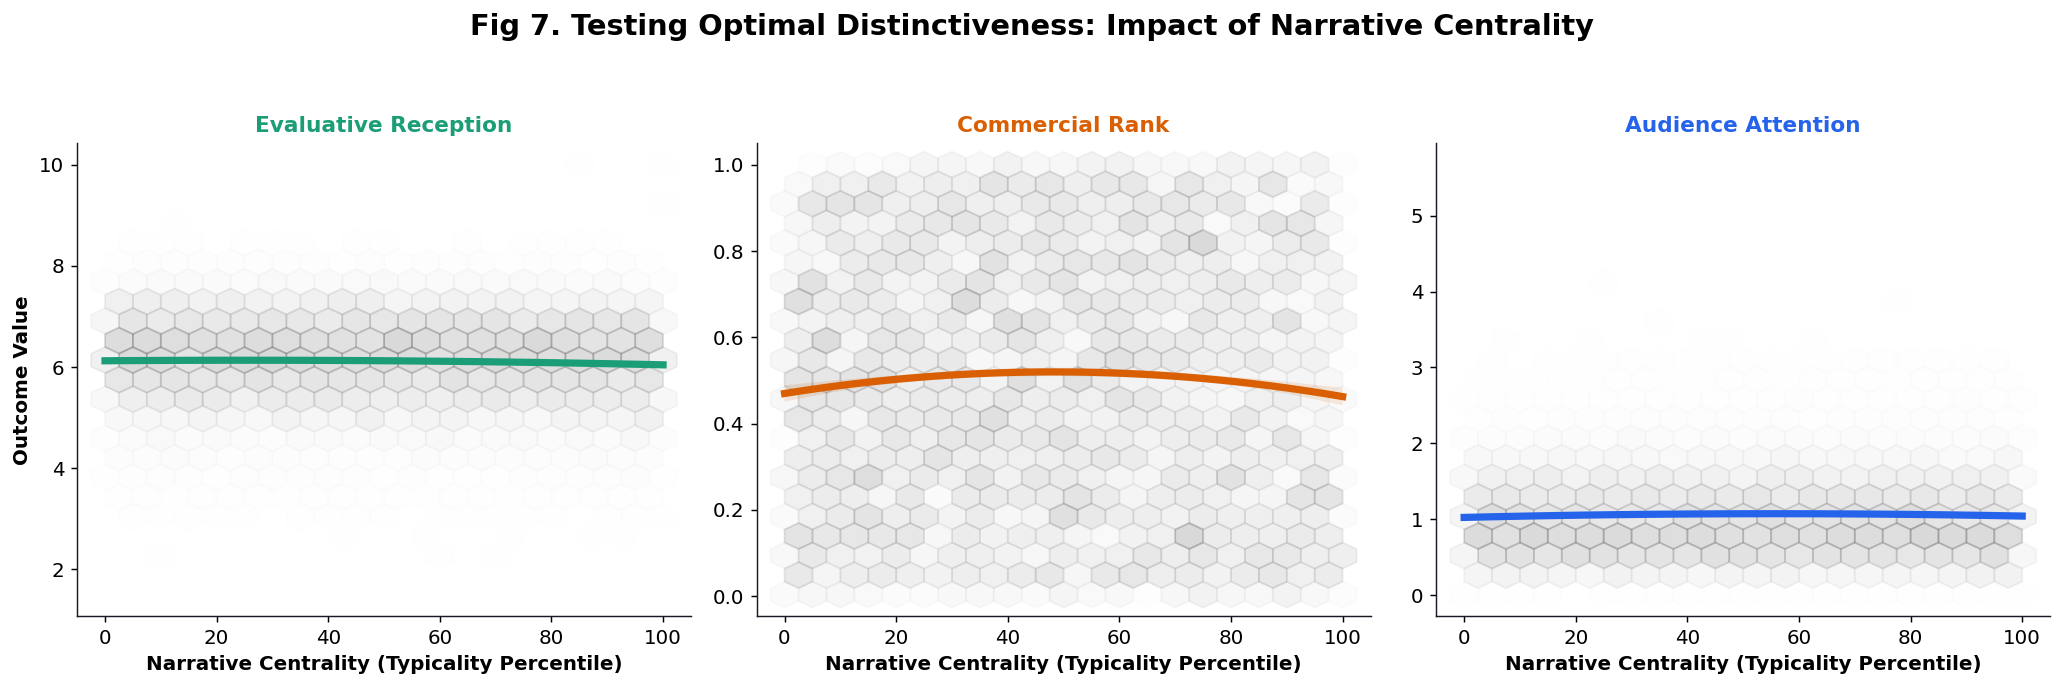

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/figures/08_bridging_success_profile.png


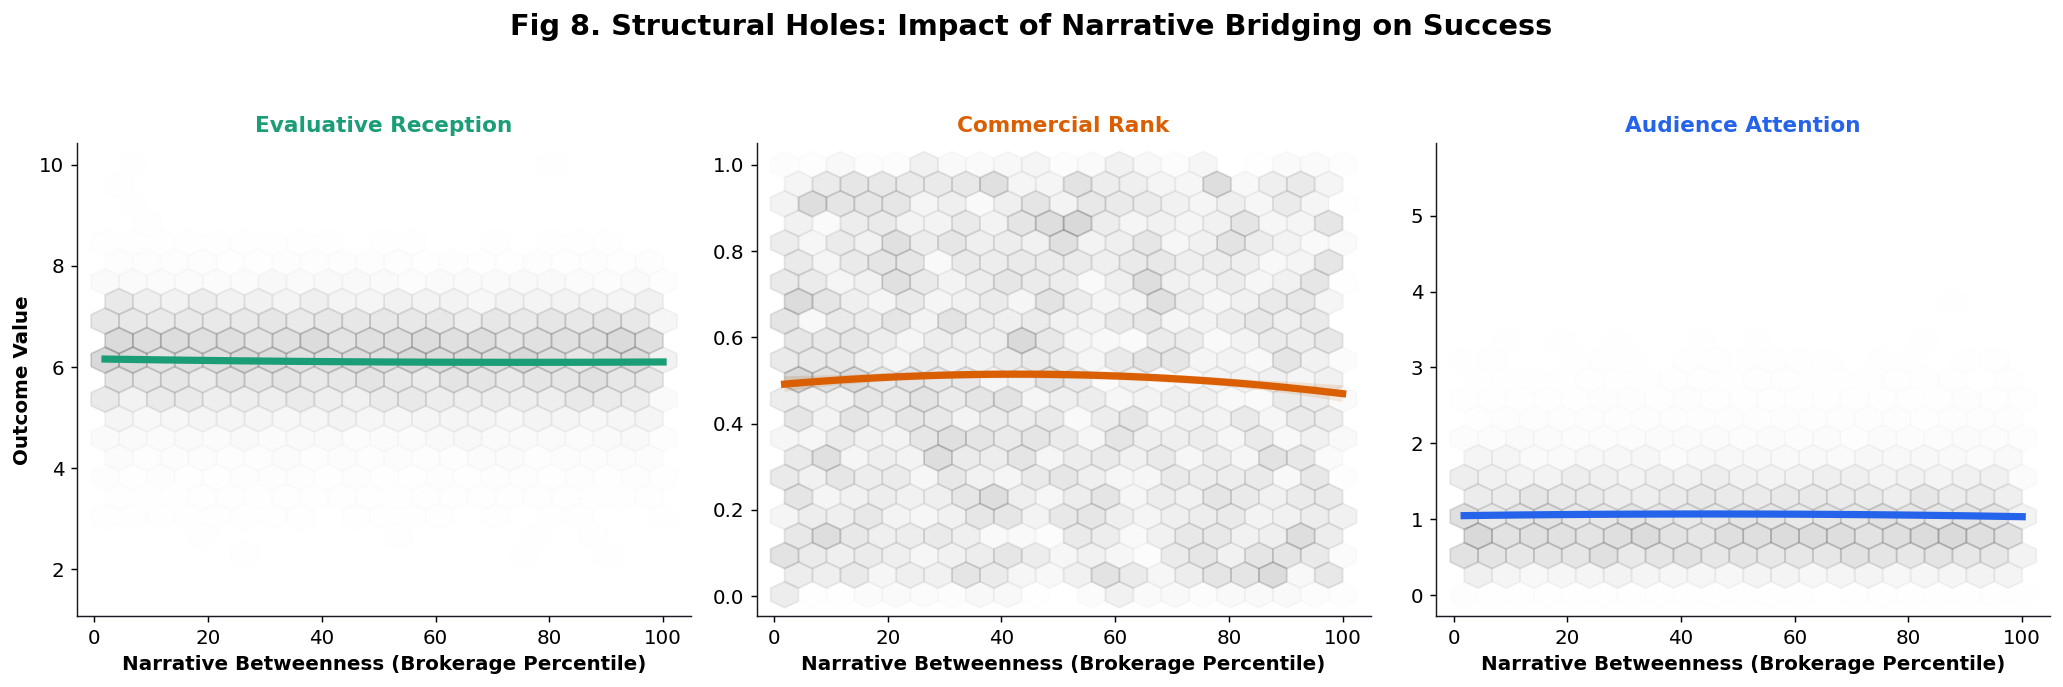

In [8]:
# Create clean percentiles for smoother X-axes
df["cent_pct"] = df[weighted_degree].rank(pct=True) * 100
df["betw_pct"] = df[betweenness].rank(pct=True) * 100

def plot_optimal_distinctiveness(x_col, x_label, filename, title):
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    for i, (out_name, out_col, color) in enumerate(outcomes):
        ax = axes[i]
        # Use seaborn regplot with order=2 to fit the quadratic (non-linear) curve with 95% CIs
        sns.regplot(data=df, x=x_col, y=out_col, scatter=False, order=2, ax=ax,
                    color=color, line_kws={"linewidth": 4})

        # Add a subtle hexbin in the background to show where the density of the films actually lies
        ax.hexbin(df[x_col], df[out_col], gridsize=20, cmap="Greys", alpha=0.15)

        ax.set_title(out_name, fontsize=12, fontweight="bold", color=color)
        ax.set_xlabel(x_label, fontweight="bold")
        if i == 0: ax.set_ylabel("Outcome Value", fontweight="bold")
        else: ax.set_ylabel("")

    plt.suptitle(title, fontsize=16, fontweight="bold", y=1.05)
    plt.tight_layout()
    save_fig(fig, filename)
    plt.show()

plot_optimal_distinctiveness("cent_pct", "Narrative Centrality (Typicality Percentile)",
                             "07_centrality_success_profile.png",
                             "Fig 7. Testing Optimal Distinctiveness: Impact of Narrative Centrality")

plot_optimal_distinctiveness("betw_pct", "Narrative Betweenness (Brokerage Percentile)",
                             "08_bridging_success_profile.png",
                             "Fig 8. Structural Holes: Impact of Narrative Bridging on Success")

## 8. Figures 9 & 10 — Result Interpretation and Final Storyline

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/figures/09_key_result_interpretation_cards.png


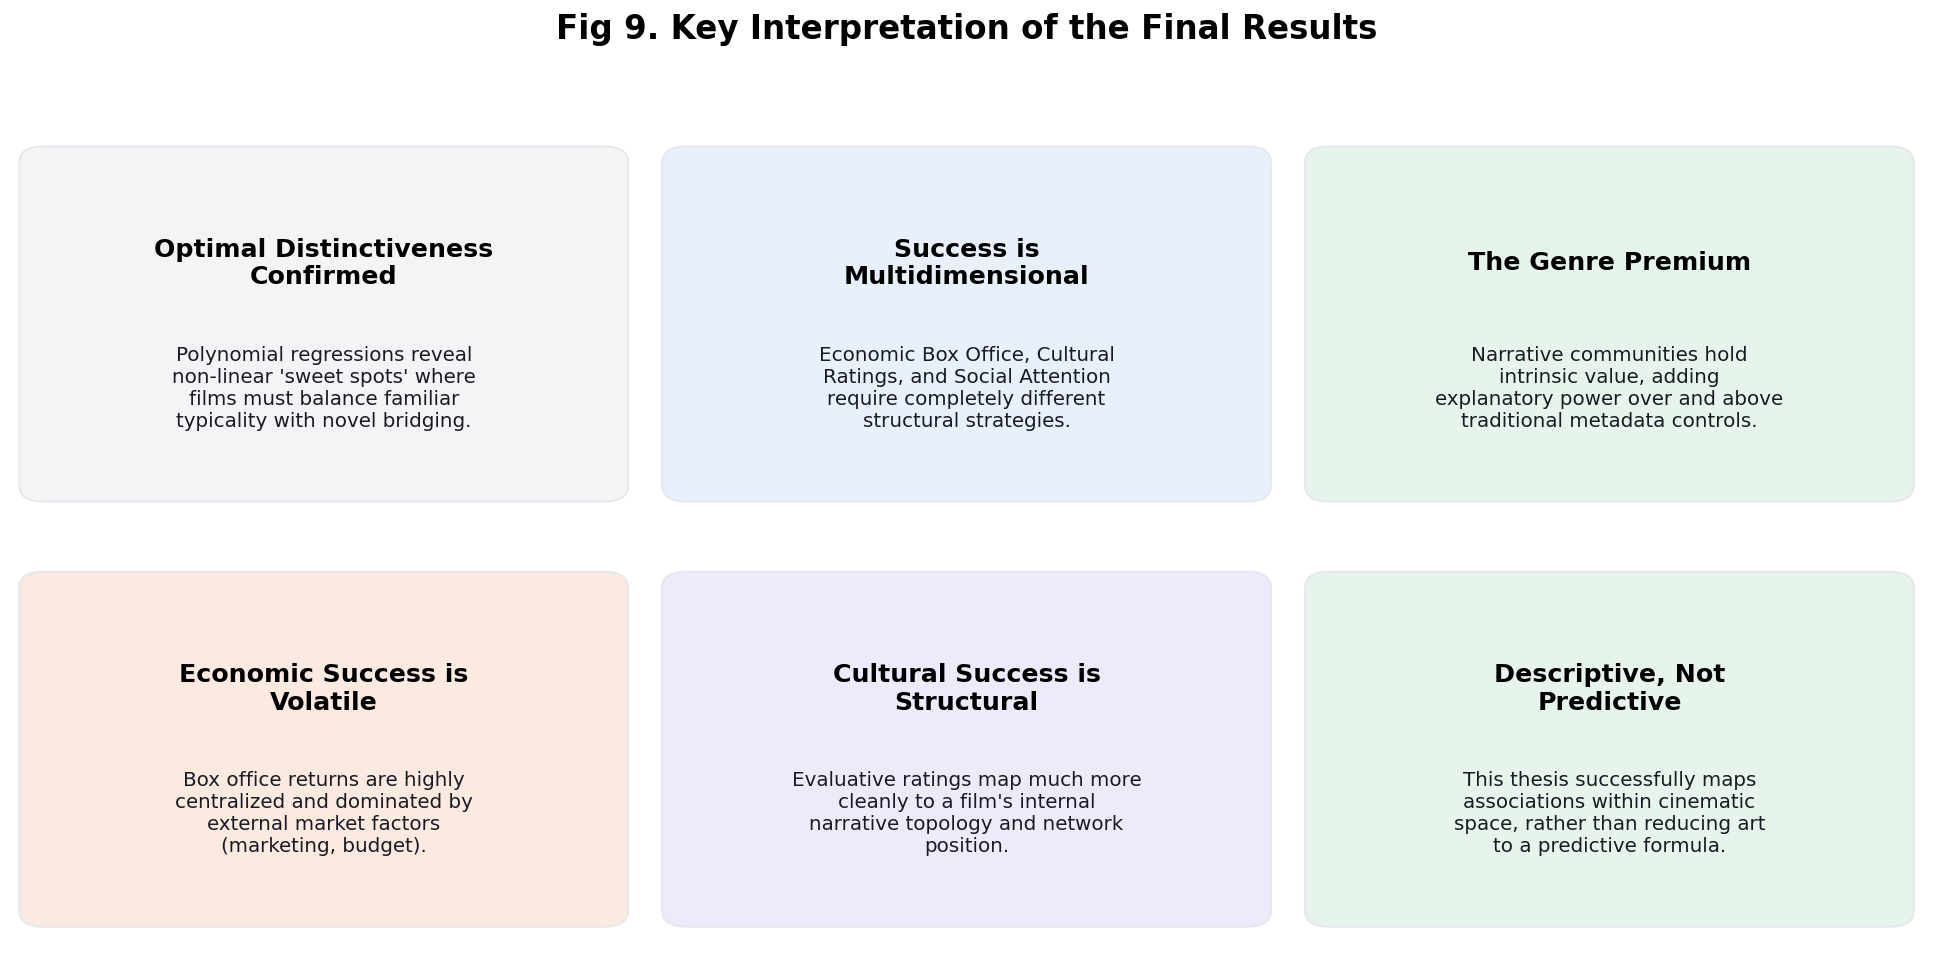

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/08_structure_success/figures/10_final_results_storyline.png


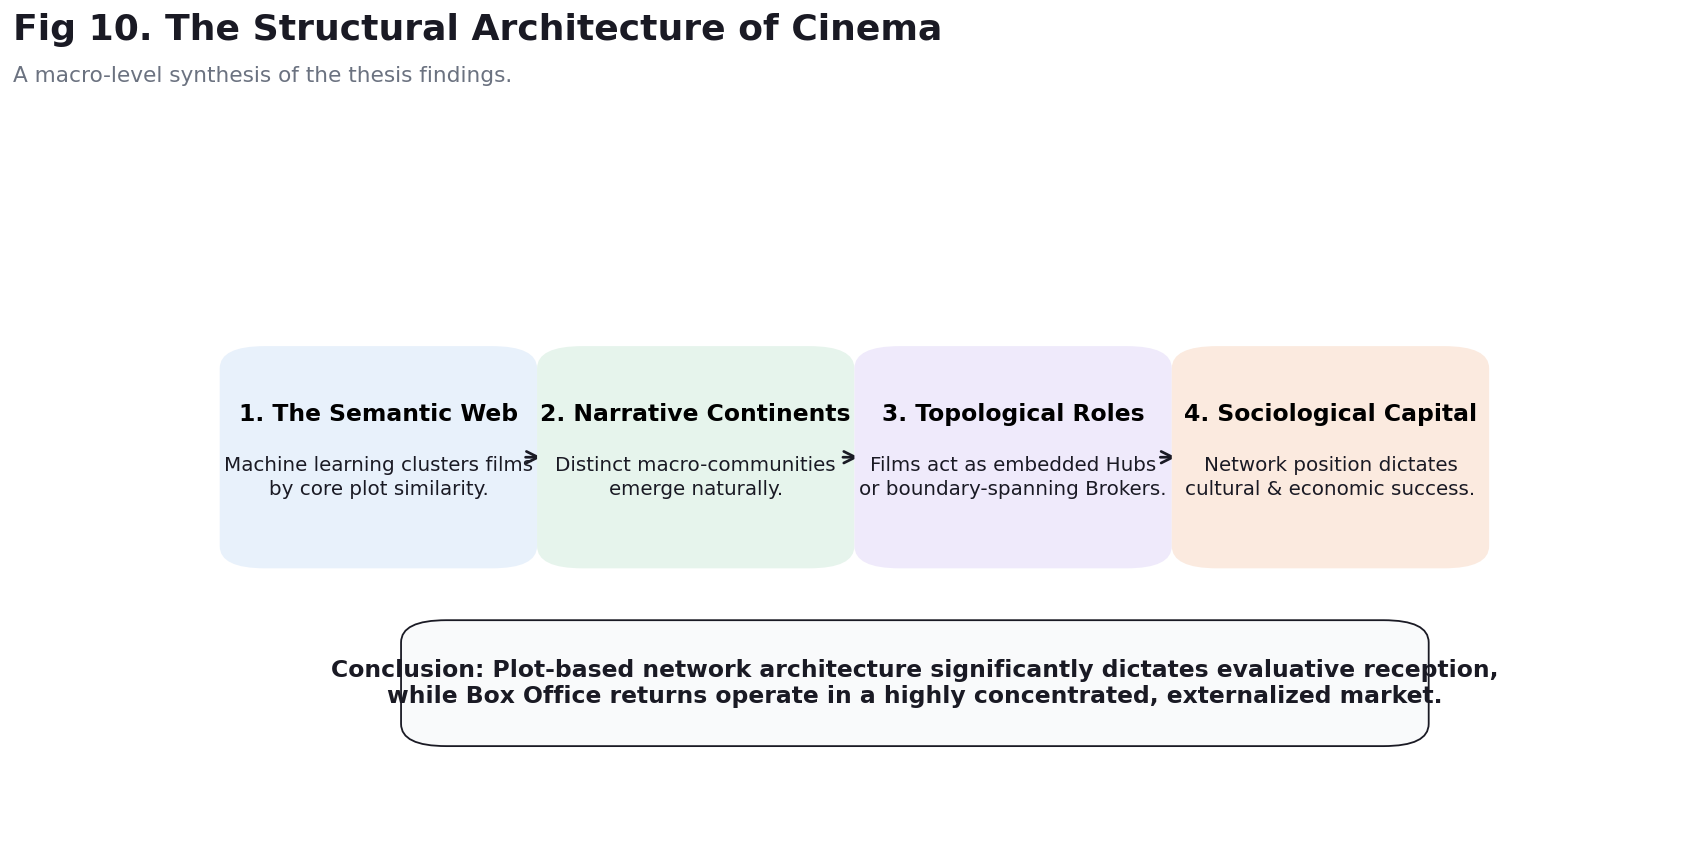

In [9]:
# FIGURE 9: Interpretation Cards
cards=[
    ("Optimal Distinctiveness Confirmed","Polynomial regressions reveal non-linear 'sweet spots' where films must balance familiar typicality with novel bridging.",COL["light_gray"]),
    ("Success is Multidimensional","Economic Box Office, Cultural Ratings, and Social Attention require completely different structural strategies.",COL["light_blue"]),
    ("The Genre Premium","Narrative communities hold intrinsic value, adding explanatory power over and above traditional metadata controls.",COL["light_green"]),
    ("Economic Success is Volatile","Box office returns are highly centralized and dominated by external market factors (marketing, budget).",COL["light_orange"]),
    ("Cultural Success is Structural","Evaluative ratings map much more cleanly to a film's internal narrative topology and network position.",COL["light_purple"]),
    ("Descriptive, Not Predictive","This thesis successfully maps associations within cinematic space, rather than reducing art to a predictive formula.",COL["light_green"]),
]
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5)); axes = axes.ravel()
for ax, (h, b, bg) in zip(axes, cards):
    ax.axis("off")
    ax.add_patch(FancyBboxPatch((.04,.08), .92, .82, boxstyle="round,pad=.03,rounding_size=.04", facecolor=bg, edgecolor=COL["grid"], lw=1))
    ax.text(.5, .64, wrap_text(h, 24), ha="center", va="center", fontsize=14, fontweight="bold")
    ax.text(.5, .33, wrap_text(b, 32), ha="center", va="center", fontsize=11, color=COL["ink"])
fig.suptitle("Fig 9. Key Interpretation of the Final Results", fontsize=18, fontweight="bold", y=.98)
plt.tight_layout(rect=[0, 0, 1, .95]); save_fig(fig, "09_key_result_interpretation_cards.png"); plt.show()

# FIGURE 10: Storyline
fig, ax = plt.subplots(figsize=(15, 7.4)); ax.axis("off"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
title_block(fig, "Fig 10. The Structural Architecture of Cinema", "A macro-level synthesis of the thesis findings.")

steps = [(.06, "1. The Semantic Web", "Machine learning clusters films\nby core plot similarity.", COL["light_blue"]),
         (.27, "2. Narrative Continents", "Distinct macro-communities\nemerge naturally.", COL["light_green"]),
         (.48, "3. Topological Roles", "Films act as embedded Hubs\nor boundary-spanning Brokers.", COL["light_purple"]),
         (.69, "4. Sociological Capital", "Network position dictates\ncultural & economic success.", COL["light_orange"])]

for i, (x, h, b, bg) in enumerate(steps):
    ax.add_patch(FancyBboxPatch((x, .38), .17, .26, boxstyle="round,pad=.02,rounding_size=.03", facecolor=bg, edgecolor="none"))
    ax.text(x+.085, .56, h, ha="center", fontsize=13, fontweight="bold")
    ax.text(x+.085, .46, b, ha="center", fontsize=11, color=COL["ink"], linespacing=1.3)
    if i < len(steps)-1:
        ax.add_patch(FancyArrowPatch((x+.18, .51), (steps[i+1][0]-.015, .51), arrowstyle="->", mutation_scale=16, lw=1.5, color=COL["ink"]))

ax.add_patch(FancyBboxPatch((.18, .14), .64, .13, boxstyle="round,pad=.02,rounding_size=.03", facecolor=COL["panel"], edgecolor=COL["ink"], linewidth=1))
ax.text(.5, .205, "Conclusion: Plot-based network architecture significantly dictates evaluative reception,\nwhile Box Office returns operate in a highly concentrated, externalized market.",
        ha="center", va="center", fontsize=13, color=COL["ink"], fontweight="bold")
save_fig(fig, "10_final_results_storyline.png"); plt.show()

In [10]:
print("\nAll 10 Figures successfully rendered and saved to Drive.")


All 10 Figures successfully rendered and saved to Drive.
